# 💻 ĐỒ ÁN MÔN HỌC: PHÂN TÍCH VÀ TRỰC QUAN DỮ LIỆU (IE313)

## Đề tài: Phân tích các yếu tố cấu hình và xây dựng mô hình dự đoán giá bán laptop

- **Đơn vị:** Trường Đại học Công nghệ Thông tin (UIT) – ĐHQG-HCM
- **Nhóm thực hiện:** Nhóm 5
  - Chu Văn Thơm - MSSV: 25410314
  - Trần Ngọc Tâm - MSSV: 25410300
  - Hồ Thiên Phúc - MSSV: 25410284
- **Mục tiêu Notebook:** Trình diễn quy trình phân tích và huấn luyện mô hình học máy end-to-end:
  1. **Nạp & Khảo sát dữ liệu thô (Data Loading)**
  2. **Làm sạch & Trích xuất đặc trưng (Data Cleaning & Feature Extraction)**
  3. **Phân tích khám phá dữ liệu (EDA - Exploratory Data Analysis)**
  4. **Xử lý giá trị ngoại lệ (Outlier Handling via IQR)**
  5. **Lọc đặc trưng thống kê (Feature Selection via Pearson Correlation & ANOVA)**
  6. **Tiền xử lý & Mã hóa (Scaling & One-Hot Encoding)**
  7. **Huấn luyện mô hình hồi quy & Đánh giá (Modeling & Evaluation)**


## 0. Cấu hình môi trường và nạp các thư viện cần thiết

Các module được thiết kế theo kiến trúc module hóa trong thư mục `src/`:

- `src.config`: Quản lý đường dẫn dữ liệu và các siêu tham số thống kê/mô hình.
- `src.data_loader`: Tải và kiểm tra tính toàn vẹn của dữ liệu.
- `src.preprocessor`: Làm sạch dữ liệu, xử lý ngoại lệ và chuẩn hóa ma trận đặc trưng.
- `src.eda`: Thống kê mô tả, trực quan hóa và kiểm định thống kê (Pearson, ANOVA).
- `src.model_pipeline`: Xây dựng Scikit-Learn Pipeline và đánh giá hệ số xác định $R^2$.


In [14]:
from src.config import (
    ALPHA_ANOVA,
    ALPHA_CORR,
    POLY_DEGREE,
    RAW_DATA_PATH,
    TARGET_COL,
)
from src.data_loader import load_data
from src.eda import (
    categorical_var_statistic,
    get_num_cat_var,
    numeric_var_statistic,
    plot_anova,
    select_categorical_variable,
    select_numberical_variable,
)
from src.model_pipeline import train_data_pipeline
from src.preprocessor import clean_data, preprocess_data, remove_outliner

## 1. Nạp và Khảo sát dữ liệu thô (Data Loading)

Dữ liệu được nạp từ tệp `laptop_price.csv` (gồm 1.303 mẫu laptop với 13 thuộc tính ban đầu). Biến mục tiêu cần dự báo là **`Price_euros`** (giá bán tính bằng Euro).


In [15]:
raw_df = load_data(RAW_DATA_PATH)
assert raw_df is not None, "Không thể tải dữ liệu thô từ RAW_DATA_PATH."
raw_df.head(10)

[THÀNH CÔNG] Đã tải dữ liệu. Kích thước: 1303 dòng, 13 cột.


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows 10,2.1kg,400.00
6,7,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16GB,256GB Flash Storage,Intel Iris Pro Graphics,Mac OS X,2.04kg,2139.97
7,8,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,256GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1158.70
8,9,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows 10,1.3kg,1495.00
9,10,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows 10,1.6kg,770.00


## 2. Tiền xử lý & Trích xuất Đặc trưng (Feature Extraction)

Hàm `clean_data()` thực hiện các bước chuẩn hóa và kỹ thuật đặc trưng:

- **Loại bỏ cột định danh:** `laptop_ID` và `Product` do không mang ý nghĩa thống kê dự báo.
- **Chuẩn hóa dạng số:** Tách bỏ đơn vị `GB` ở `Ram`, `kg` ở `Weight` và ép về kiểu số thực.
- **Xử lý giá trị khuyết (Missing Values):** Điền trung vị (median) cho biến số và yếu vị (mode) cho biến phân loại.
- **Trích xuất đặc trưng con từ các cột phức hợp:**
  - `ScreenResolution` $\rightarrow$ `Touchscreen` (0/1), `Ips` (0/1), `Resolution` (ví dụ: `1920x1080`).
  - `Cpu` $\rightarrow$ `Cpu_Speed` (xung nhịp GHz), `Cpu_Brand` (Intel Core i3/i5/i7, AMD...).
  - `Memory` $\rightarrow$ `SSD`, `HDD`, `Flash_Storage`, `Hybrid` (dung lượng tính theo GB).
  - `Gpu` $\rightarrow$ `Gpu_Brand` (Intel, Nvidia, AMD), `Gpu_Type` (GeForce, Quadro, Radeon...).


In [16]:
assert raw_df is not None, "Không thể tải dữ liệu thô từ RAW_DATA_PATH."
df = clean_data(raw_df)
df.head(3)

Đang tiến hành làm sạch dữ liệu...


[THÀNH CÔNG] Làm sạch dữ liệu hoàn tất! Kích thước: 1303 dòng, 18 cột.


,Company,TypeName,Inches,Ram,OpSys,Weight,Price_euros,Touchscreen,Ips,Resolution,Cpu_Speed,Cpu_Brand,SSD,HDD,Flash_Storage,Hybrid,Gpu_Brand,Gpu_Type
0,Apple,Ultrabook,13.3,8,macOS,1.37,1339.69,0,1,2560x1600,2.3,Intel Core i5,128,0,0,0,Intel,Intel Integrated Graphics
1,Apple,Ultrabook,13.3,8,macOS,1.34,898.94,0,0,1440x900,1.8,Intel Core i5,0,0,128,0,Intel,Intel Integrated Graphics
2,HP,Notebook,15.6,8,No OS,1.86,575.00,0,0,1920x1080,2.5,Intel Core i5,256,0,0,0,Intel,Intel Integrated Graphics


## 3. Phân tích Khám phá Dữ liệu (EDA)

### 3.1. Phân loại biến & Thống kê mô tả biến số (Numerical Features)

Phân tách dữ liệu thành nhóm biến số (numeric) và biến phân loại (categorical), sau đó trực quan hóa phân phối qua biểu đồ Histogram và Boxplot.


In [17]:
numerical_cols, categorical_cols = get_num_cat_var(df)

=== THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ ===
                count         mean         std     min    25%     50%  \
Inches         1303.0    15.017191    1.426304   10.10   14.0   15.60   
Ram            1303.0     8.382195    5.084665    2.00    4.0    8.00   
Weight         1303.0     2.038734    0.665475    0.69    1.5    2.04   
Price_euros    1303.0  1123.686992  699.009043  174.00  599.0  977.00   
Touchscreen    1303.0     0.147352    0.354593    0.00    0.0    0.00   
Ips            1303.0     0.280123    0.449231    0.00    0.0    0.00   
Cpu_Speed      1303.0     2.298772    0.506340    0.90    2.0    2.50   
SSD            1303.0   183.732924  186.966903    0.00    0.0  256.00   
HDD            1303.0   413.783576  515.818779    0.00    0.0    0.00   
Flash_Storage  1303.0     4.555641   30.274090    0.00    0.0    0.00   
Hybrid         1303.0     8.831926   92.567185    0.00    0.0    0.00   

                   75%     max  
Inches           15.60    18.4  
Ram               8.00

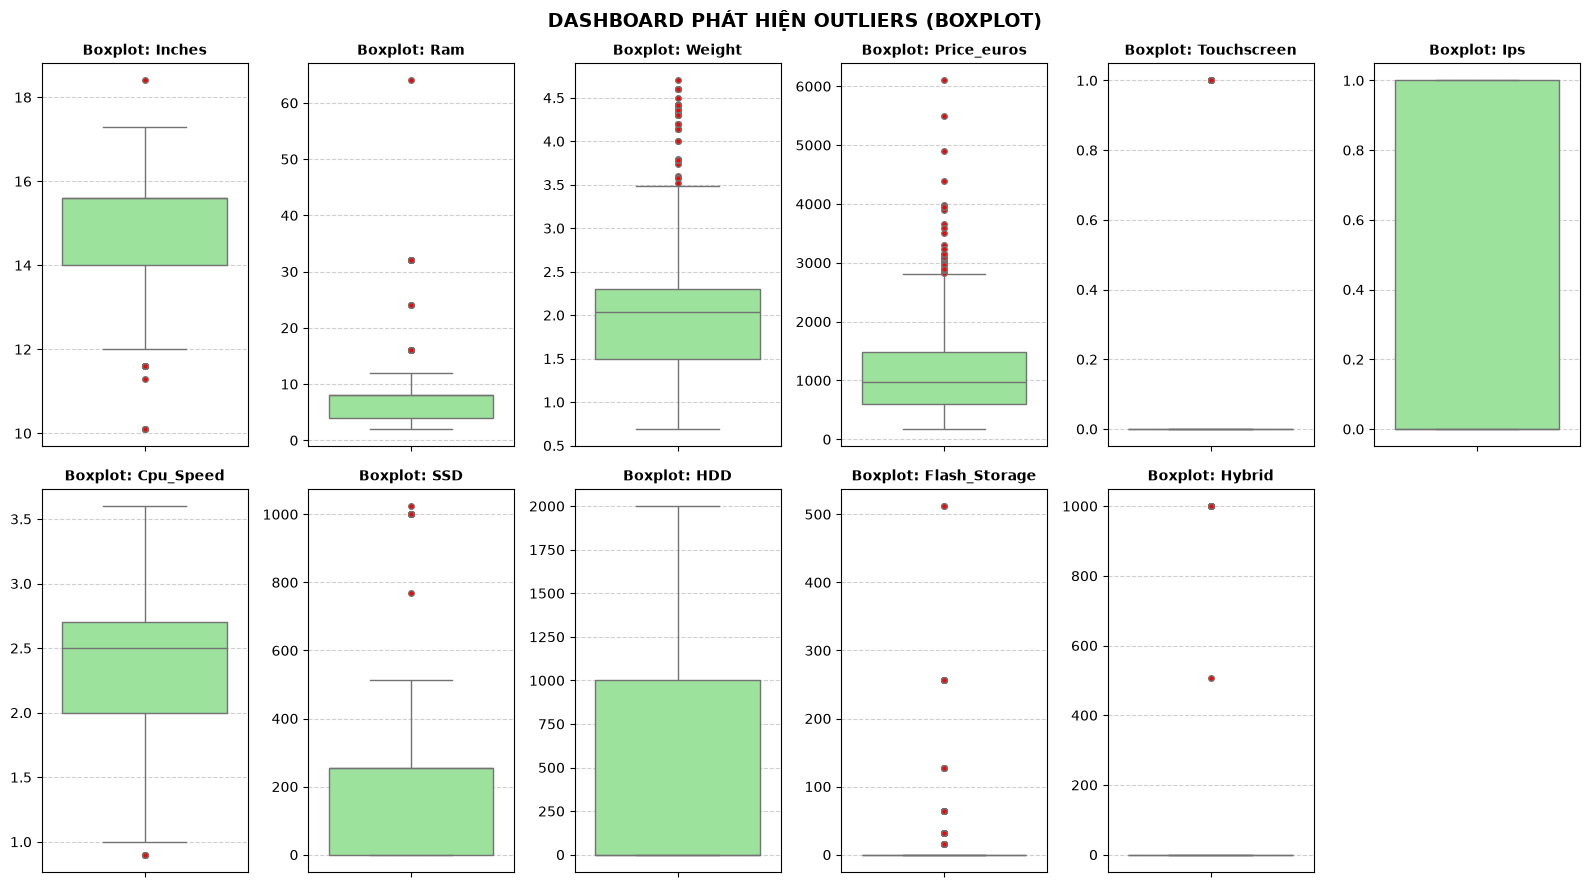

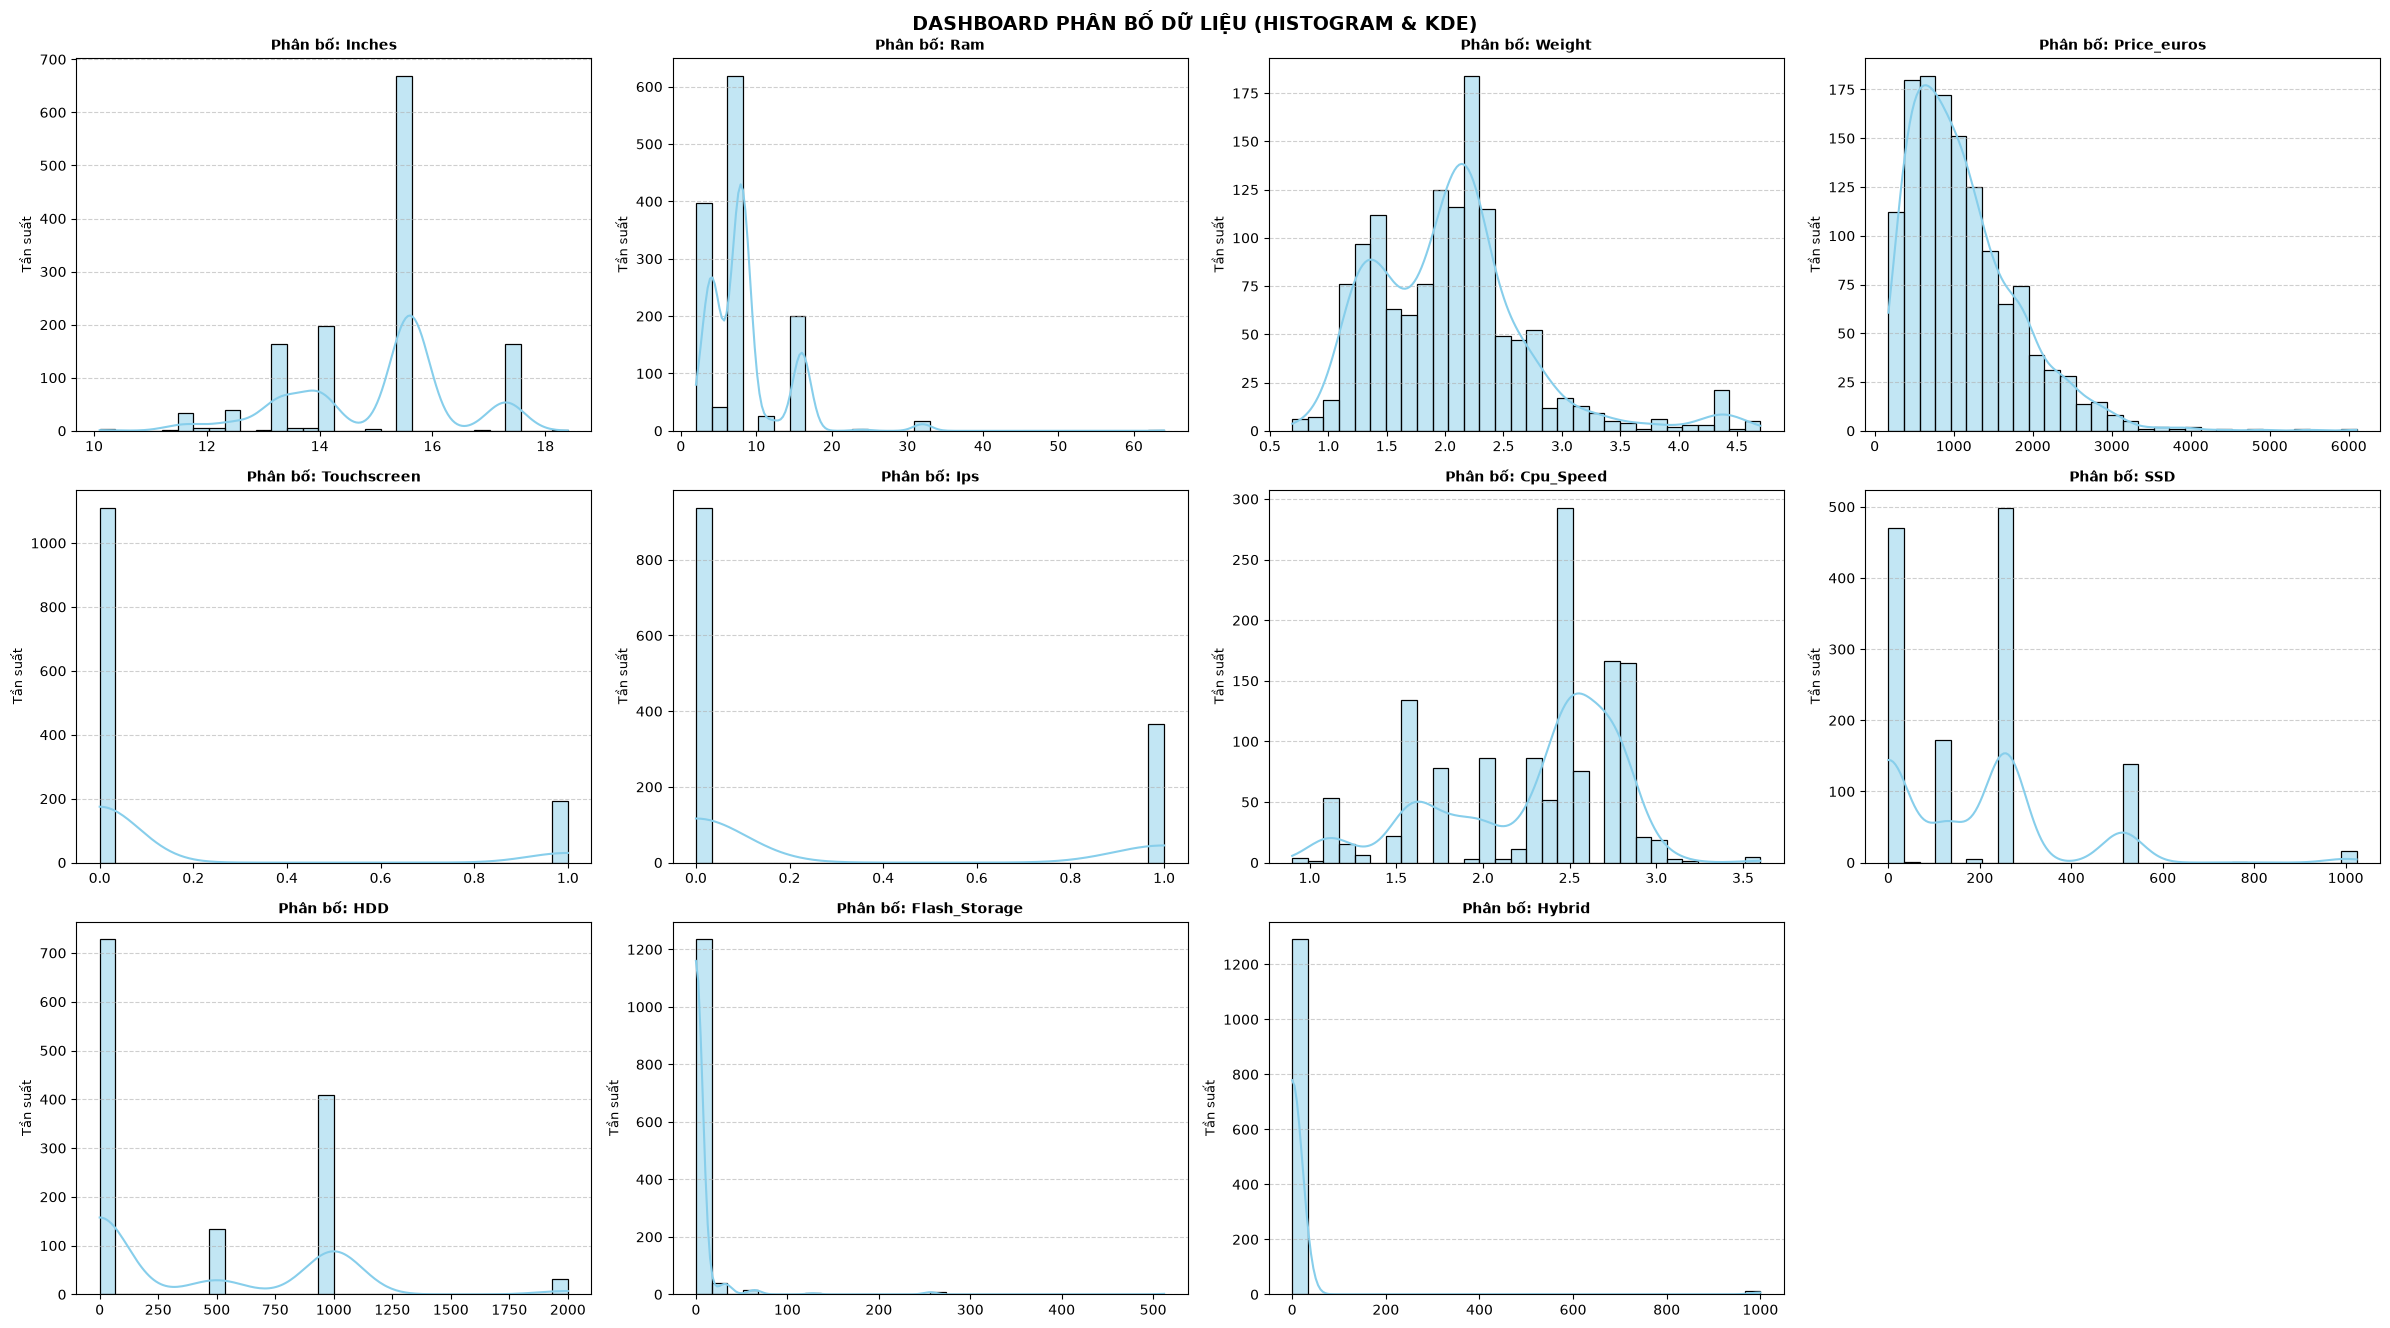

In [18]:
numeric_var_statistic(df, numerical_cols=numerical_cols)

> **Nhận xét phân phối biến số:**
>
> - Biến mục tiêu `Price_euros`: Phân phối lệch phải, tập trung chủ yếu trong vùng 600 – 1.500 EUR; xuất hiện một số mẫu giá cao đột biến trên 2.800 EUR (ngoại lệ).
> - `Ram`: Tập trung phổ biến ở 8GB và 16GB. Mức 4GB thuộc phân khúc giá rẻ; 32GB và 64GB xuất hiện ở các dòng máy trạm/gaming chuyên nghiệp.
> - `SSD`: Phổ biến nhất là 256GB và 512GB.

### 3.2. Thống kê mô tả biến phân loại (Categorical Features)

Khảo sát tần suất xuất hiện và phân bố mức giá theo từng danh mục thông qua biểu đồ tần suất (Count Plot) và Boxplot.


=== Tần suất cho biến: Company ===
           Số lượng  Tỷ lệ (%)
Company                       
Dell            297  22.793553
Lenovo          297  22.793553
HP              274  21.028396
Asus            158  12.125863
Acer            103   7.904835
MSI              54   4.144282
Toshiba          48   3.683807
Apple            21   1.611665
Samsung           9   0.690714
Razer             7   0.537222
Mediacom          7   0.537222
Microsoft         6   0.460476
Xiaomi            4   0.306984
Vero              4   0.306984
Chuwi             3   0.230238
Google            3   0.230238
Fujitsu           3   0.230238
LG                3   0.230238
Huawei            2   0.153492
----------------------------------------
=== Tần suất cho biến: TypeName ===
                    Số lượng  Tỷ lệ (%)
TypeName                               
Notebook                 727  55.794321
Gaming                   205  15.732924
Ultrabook                196  15.042210
2 in 1 Convertible       121   9.2862

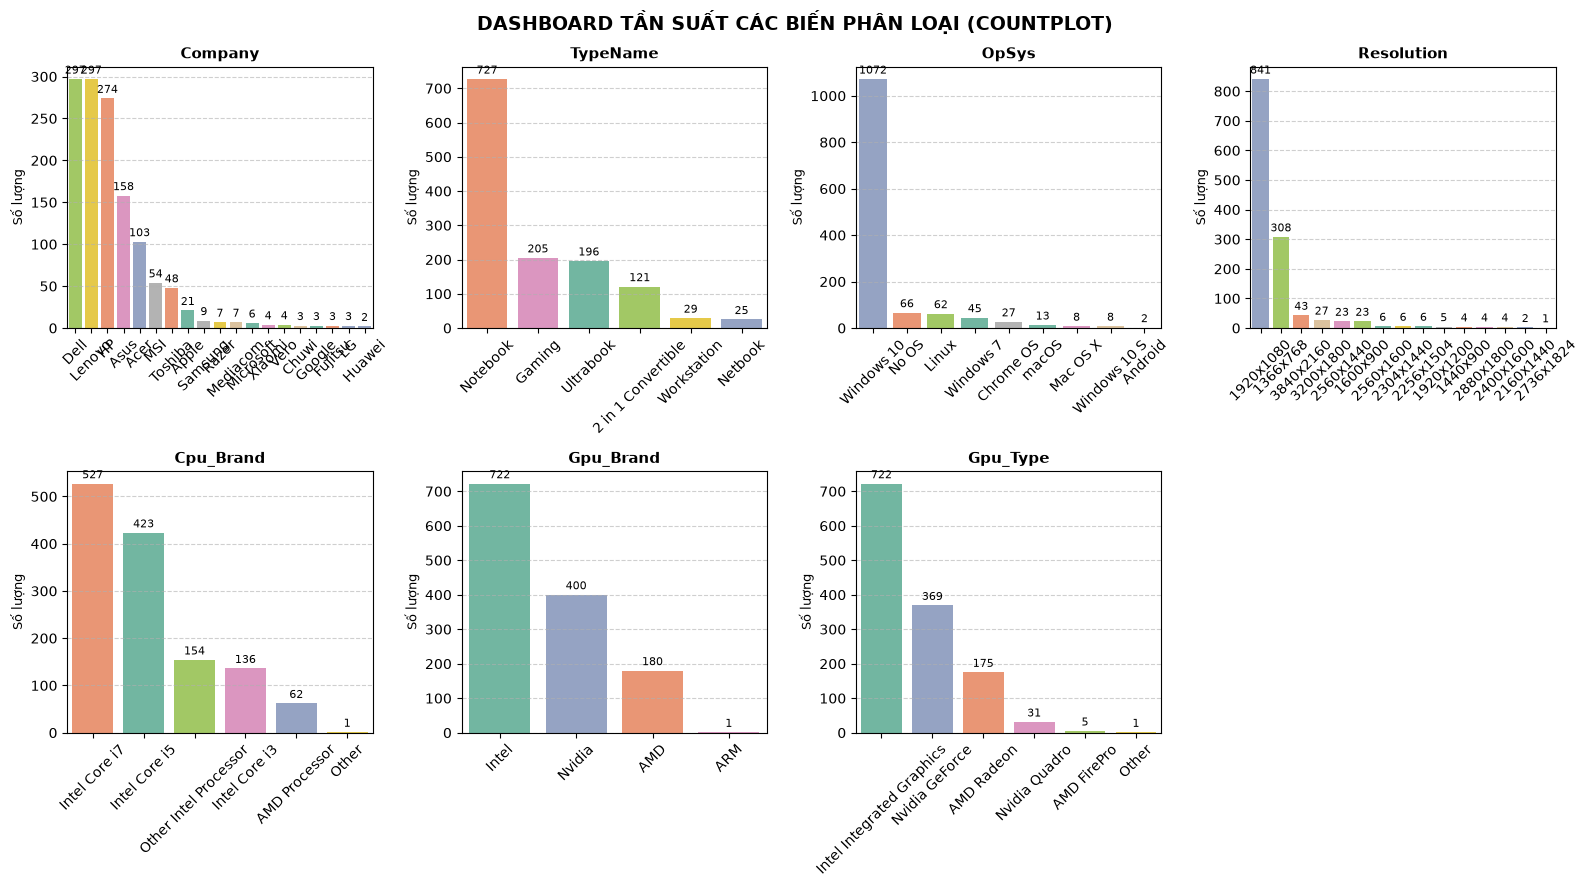

In [19]:
categorical_var_statistic(df, categorical_cols=categorical_cols)

> **Nhận xét biến phân loại:**
>
> - `Company`: Dell (297), Lenovo (297) và HP (274) là ba hãng chiếm thị phần lớn nhất trong tập dữ liệu.
> - `TypeName`: Dòng Notebook chiếm đa số, tiếp theo là Ultrabook và Gaming. Dòng Workstation và Gaming có phân phối giá cao vượt trội.

---

## 4. Xử lý giá trị ngoại lệ (Outlier Handling)

Sử dụng phương pháp **Khoảng tứ phân vị (IQR - Interquartile Range)** trên biến mục tiêu `Price_euros`:
$$\text{IQR} = Q_3 - Q_1, \quad \text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$$
Các mẫu máy có giá bán vượt cận trên (~2.800 EUR) được loại bỏ để tránh làm méo mó mô hình hồi quy. Kích thước dữ liệu sau khi lọc giảm từ 1.303 xuống còn **1.274 dòng** (loại 29 ngoại lệ).


In [20]:
df = remove_outliner(df, [TARGET_COL])
df.head(3)

[THÀNH CÔNG] Xóa ngoại lệ hoàn tất! Kích thước: 1274 dòng, 18 cột.


,Company,TypeName,Inches,Ram,OpSys,Weight,Price_euros,Touchscreen,Ips,Resolution,Cpu_Speed,Cpu_Brand,SSD,HDD,Flash_Storage,Hybrid,Gpu_Brand,Gpu_Type
0,Apple,Ultrabook,13.3,8,macOS,1.37,1339.69,0,1,2560x1600,2.3,Intel Core i5,128,0,0,0,Intel,Intel Integrated Graphics
1,Apple,Ultrabook,13.3,8,macOS,1.34,898.94,0,0,1440x900,1.8,Intel Core i5,0,0,128,0,Intel,Intel Integrated Graphics
2,HP,Notebook,15.6,8,No OS,1.86,575.00,0,0,1920x1080,2.5,Intel Core i5,256,0,0,0,Intel,Intel Integrated Graphics


## 5. Lọc đặc trưng có ý nghĩa thống kê (Feature Selection)

### 5.1. Lọc biến số bằng Hệ số tương quan Pearson

Tính ma trận tương quan giữa các biến số với biến mục tiêu `Price_euros`. Giữ lại các đặc trưng có $|r| > 0.2$.


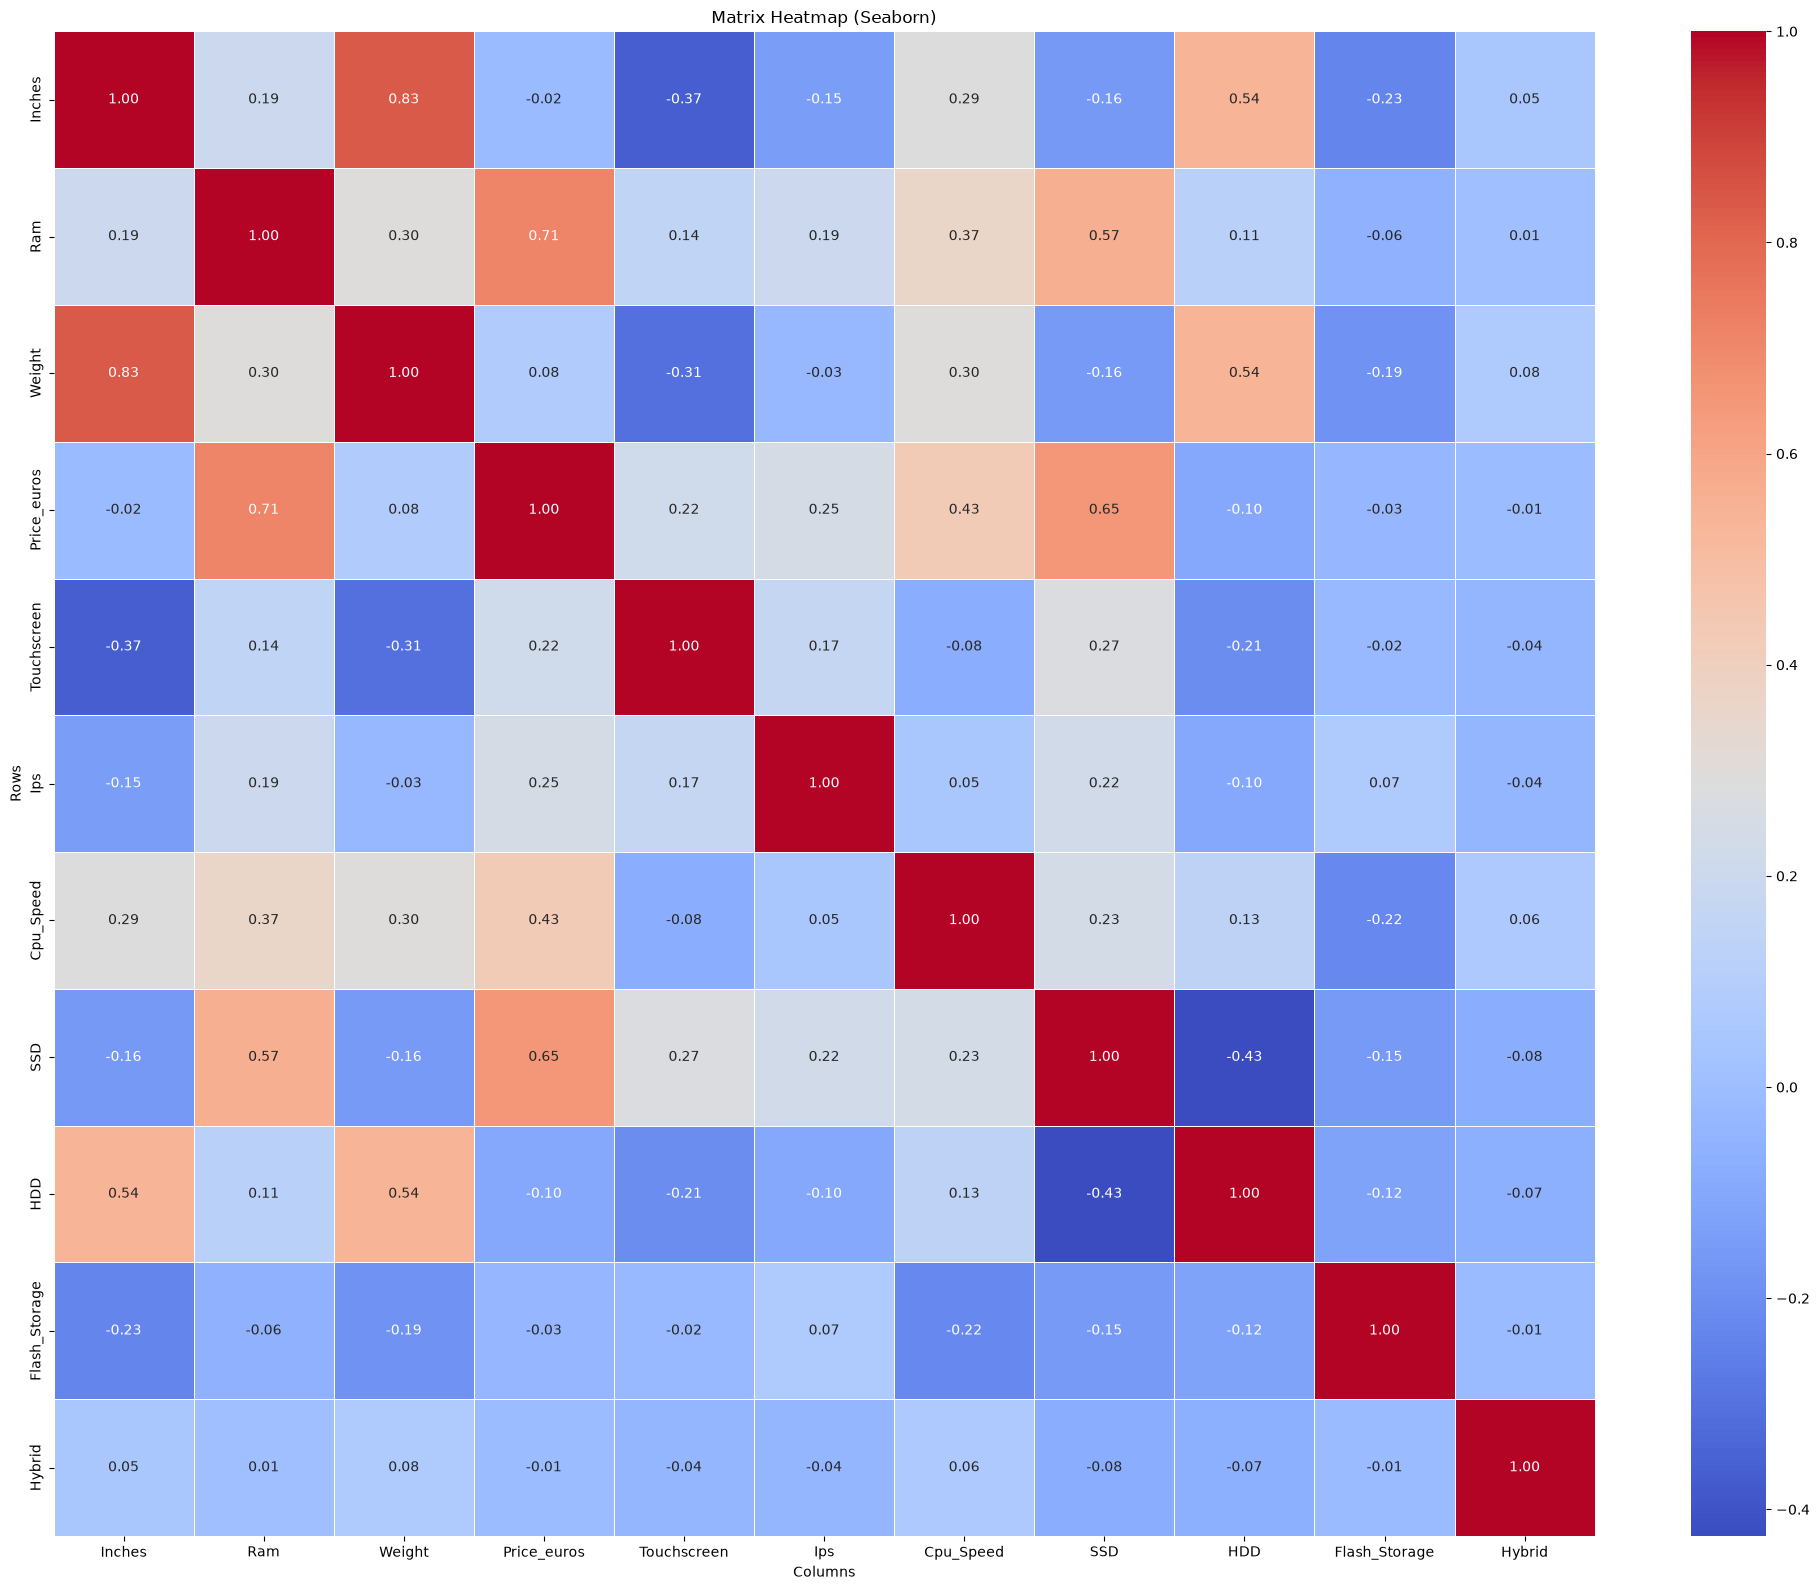

Các cột có |corr| > 0.2 với Price_euros:
['Ram', 'Touchscreen', 'Ips', 'Cpu_Speed', 'SSD']


In [21]:
numerical = select_numberical_variable(
    df, series_name=numerical_cols, target=TARGET_COL, alpha=ALPHA_CORR
)

> **Kết quả tương quan Pearson:**
>
> - `Ram` ($r = 0.71$) và `SSD` ($r = 0.65$) có tương quan thuận rất mạnh với giá bán.
> - `Cpu_Speed` ($r = 0.42$), `Ips` ($r = 0.24$), `Touchscreen` ($r = 0.20$) đạt điều kiện chọn lọc.
> - `Inches`, `Weight`, `HDD`, `Flash_Storage`, `Hybrid` bị loại do tương quan yếu ($|r| \le 0.2$).

### 5.2. Lọc biến phân loại bằng Kiểm định One-way ANOVA

Thực hiện kiểm định giả thuyết ANOVA một yếu tố giữa từng biến phân loại và `Price_euros`. Lựa chọn các biến có ý nghĩa thống kê ($p\text{-value} < 0.05$).


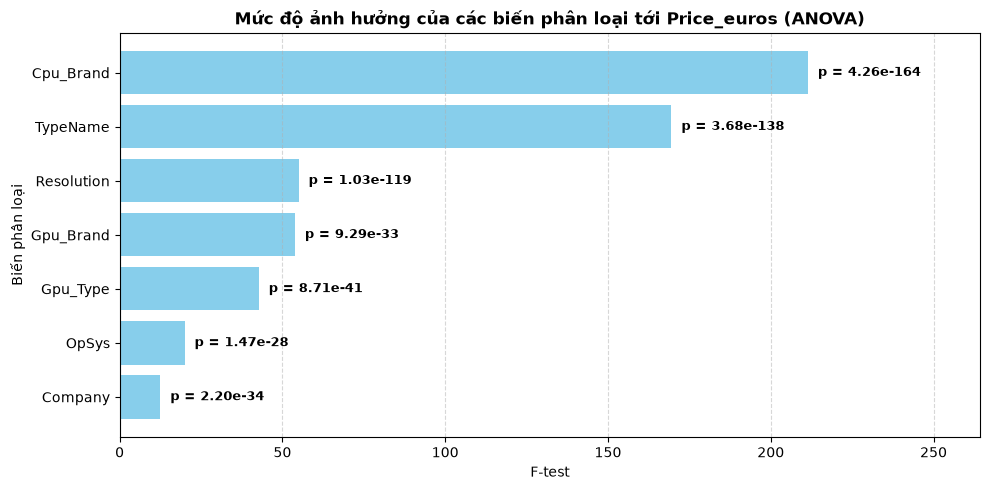

In [22]:
categorical = select_categorical_variable(
    df, categorical_cols, target=TARGET_COL, alpha=ALPHA_ANOVA
)
plot_anova(df, series=categorical_cols, target=TARGET_COL, alpha=ALPHA_ANOVA)

> **Kết quả ANOVA:**
> Toàn bộ 7 biến phân loại (`Company`, `TypeName`, `OpSys`, `Resolution`, `Cpu_Brand`, `Gpu_Brand`, `Gpu_Type`) đều có $p\text{-value} \ll 0.05$, chứng tỏ sự khác biệt về giá bán giữa các nhóm danh mục là có ý nghĩa thống kê rất cao.

---

## 6. Tiền xử lý dữ liệu cho Mô hình Hồi quy (Preprocessing)

Chuẩn bị ma trận dữ liệu huấn luyện thông qua hàm `preprocess_data()`:

1. **Chuẩn hóa Z-score (`StandardScaler`):** Đưa các biến số liên tục (`Ram`, `SSD`, `Cpu_Speed`) về phân phối chuẩn (mean = 0, std = 1).
2. **Mã hóa One-Hot (`pd.get_dummies` với `drop_first=True`):** Mã hóa 7 biến phân loại thành các biến giả, loại trừ cột đầu tiên để tránh hiện tượng đa cộng tuyến.
3. Giữ nguyên dạng nhị phân (0/1) cho `Touchscreen` và `Ips` (`ignore_col`).
   $\rightarrow$ Ma trận dữ liệu mở rộng thành **63 chiều đặc trưng đầu vào** và **1 cột mục tiêu** `Price_euros` (tổng cộng 64 cột).


In [23]:
procesed_df = preprocess_data(
    df, categorical, numerical, ignore_col=["Ips", "Touchscreen"], target=TARGET_COL
)

Đang tiến hành tiền xử lý dữ liệu ...
[THÀNH CÔNG] Tiền xử lý hoàn tất! Kích thước dữ liệu mới: 1274 dòng, 64 cột.


## 7. Huấn luyện Mô hình Pipeline & Đánh giá Hiệu năng

Xây dựng Scikit-Learn Pipeline gồm: `StandardScaler` $\rightarrow$ `PolynomialFeatures` $\rightarrow$ `LinearRegression`.
Dữ liệu được chia thành tập Huấn luyện (Train - 80%) và tập Kiểm tra (Test - 20%) với `random_state=0` cố định để đảm bảo tính tái lập.


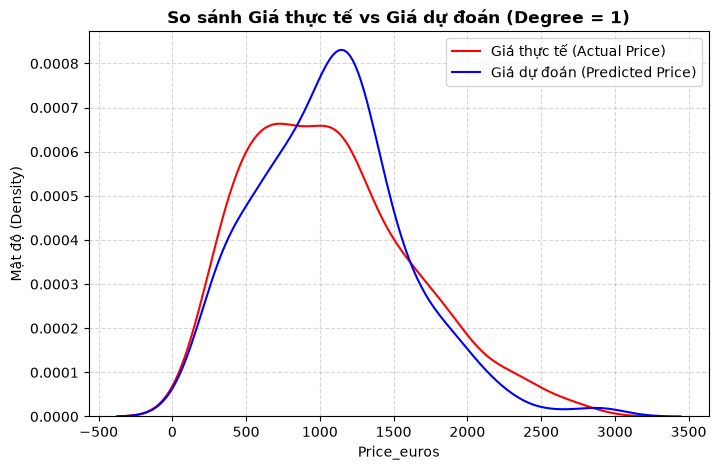

(0.7968093656804663, 0.7724543378288078)


In [24]:
print(train_data_pipeline(procesed_df, degree=POLY_DEGREE, target=TARGET_COL))

## 8. Kết luận & Đánh giá mô hình

- **Hiệu năng mô hình hồi quy tuyến tính (bậc 1):**
  - $R^2_{\text{train}} \approx 0.7968$
  - $R^2_{\text{test}} \approx 0.7725$
  - Chênh lệch giữa Train và Test rất nhỏ ($0.0244$), chứng minh mô hình tổng quát hóa tốt, không bị overfitting.
- **So sánh với đa thức bậc cao:**
  - Theo thực nghiệm trong báo cáo, khi tăng lên bậc 2 ($R^2_{\text{test}} \approx 0.4730$) hoặc bậc 3 ($R^2_{\text{test}} < 0$), số lượng đặc trưng tương tác tăng vọt gây hiện tượng quá khớp (overfitting) nghiêm trọng.
  - Vì vậy, hồi quy đa thức bậc 1 (tuyến tính) là mô hình tối ưu nhất cho bài toán.
- **Yếu tố cấu hình quan trọng nhất:**
  - `Ram` ($r = 0.71$) và `SSD` ($r = 0.65$) là hai thành phần ảnh hưởng quyết định nhất đến giá thành máy tính.
  - Dòng sản phẩm (`TypeName`: Workstation, Gaming) và hãng vi xử lý (`Cpu_Brand`) là các biến phân loại chi phối mạnh nhất đến giá bán.
